# Tutorial 2: Modelling with PyTracerLab in the Bayesian Statistical Framework
Here we show how to use the PyTracerLab package to perform a basic standard application of lumped parameter models (see Tutorial 1), but with an important change. We still calibrate parameter values of the lumped parameter model from observations of tracer concentrations in an observation well, but here we perform this process in a Bayesian statistical framework using a Markov-chain Monte Carlo sampler.

In [1]:
import PyTracerLab.model as ism
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

## 1. Load (Synthetic) Observation Data
See Tutorial 4 on how this data is generated.

In [2]:
# load input series
# this would be the tracer concentration in precipitation or recharge in a
# practical problem
file_name = "example_input_series_1tracer.csv"
data = np.genfromtxt(
    file_name,
    delimiter=",",
    dtype=["<U7", float],
    encoding="utf-8",
    skip_header=1
)

timestamps = np.array([datetime.strptime(row[0], r"%Y-%m") for row in data])
input_series = np.array([float(row[1]) for row in data])

# load observation series
# this would be the measured tracer concentration in groundwater in a
# practical problem
file_name = "example_observation_series_1tracer.csv"
data = np.genfromtxt(
    file_name,
    delimiter=",",
    dtype=["<U7", float],
    encoding="utf-8",
    skip_header=1
)

timestamps = np.array([datetime.strptime(row[0], r"%Y-%m") for row in data])
obs_series = np.array([float(row[1]) for row in data])

# load full system output series
# this would be the true tracer concentration in groundwater in a practical
# problem; this is not available in practice
file_name = "example_output_series_1tracer.csv"
data = np.genfromtxt(
    file_name,
    delimiter=",",
    dtype=["<U7", float],
    encoding="utf-8",
    skip_header=1
)

timestamps = np.array([datetime.strptime(row[0], r"%Y-%m") for row in data])
output_series = np.array([float(row[1]) for row in data])

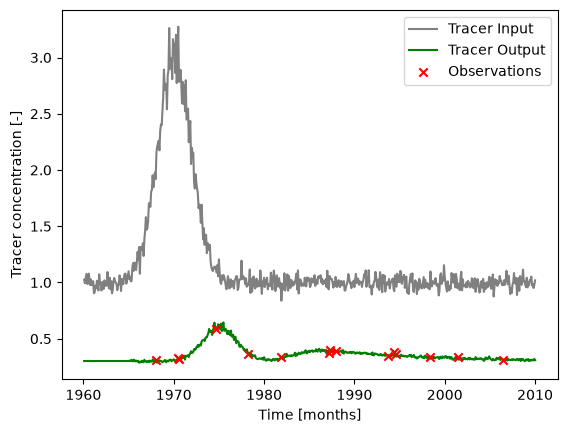

In [3]:
### plot input series, output series, and observations

# get observation timesteps
timesteps = [t.year + t.month / 12.0 for t in timestamps]

# create figure
fig, ax = plt.subplots(1, 1)
# plot input series
ax.plot(
    timesteps,
    input_series,
    label="Tracer Input",
    c="grey"
)
# plot output series
ax.plot(
    timesteps,
    output_series,
    label="Tracer Output",
    c="green"
)
# plot observations
ax.scatter(
    timesteps,
    obs_series,
    label="Observations",
    color="red",
    marker="x",
    zorder=10
)
ax.set_xlabel("Time [months]")
ax.set_ylabel("Tracer concentration [-]")
ax.legend()
plt.show()

## 2. Run DREAM (MCMC) for Model Parameters

In [4]:
t_half = 12.3 * 12.0
lambda_ = np.log(2.0) / t_half

### define model (use the same structure / units as the true model)
# time step is 1 month
m = ism.Model(
    dt=1.0,
    lambda_=lambda_,
    input_series=input_series,
    target_series=obs_series,
    steady_state_input=1., # this is the true value
)

# add an exponential-piston-flow unit
# define the initial model parameters for inference
epm_mtt_init = 12 * 40 # 40 years
epm_eta_init = 1.5
m.add_unit(
    ism.EPMUnit(mtt=epm_mtt_init, eta=epm_eta_init),
    fraction=.8, # 80 percent of the overall response; is the true value
    bounds=[(12. * 39., 12.0 * 41.), (1.4, 1.6)],
    prefix="epm"
)

# add a piston-flow unit
# define the true model parameters
pm_mtt_init = 12 * 5 # 5 years
m.add_unit(
    ism.PMUnit(mtt=pm_mtt_init),
    fraction=.2, # 20 percent of the overall response, is the true value
    bounds=[(12. * 4, 12.0 * 6.)],
    prefix="pm"
)

In [5]:
# create a solver
solver = ism.Solver(m)
# run DREAM (8 chains, as in the examples of the PyTracerLab paper)
res = solver.dream_sample(
    n_samples=4000, # samples per chain after burn-in and thinning
    burn_in=4000,
    thin=1,
    n_chains=8,
    n_diff_pairs=2,
    cr=[i / 5 for i in range(1, 6)],
    sigma=0.01,
    return_sim=True,
    random_state=1234,
    set_model_state=False
)

In [6]:
# print order of parameters in results dictionary
print(res["param_names"])

['epm.eta', 'epm.mtt', 'pm.mtt']


{'epm.eta': 1.006334049172224, 'epm.mtt': 1.0053137677893553, 'pm.mtt': 1.005395309800939}
4


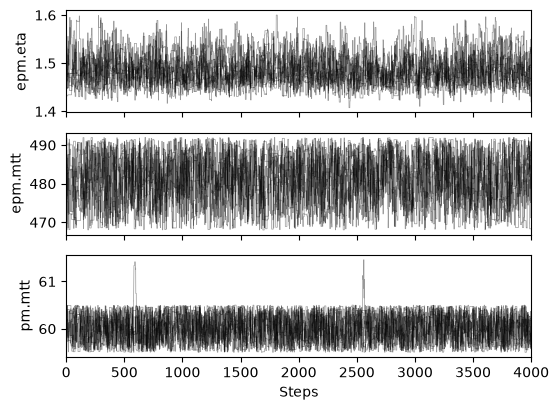

In [7]:
# plot chains to inspect convergence
fig, ax = plt.subplots(res["samples_chain"].shape[2], 1, figsize=(6, res["samples_chain"].shape[2] * 1.5), sharex=True)

for i in range(res["samples_chain"].shape[2]):
    for j in range(res["samples_chain"].shape[0]):
        ax[i].plot(res["samples_chain"][j, :, i], c="k", lw=.5, alpha=0.4)
    ax[i].set_ylabel(m.param_keys(free_only=True)[i])
    ax[i].set_xlim(0, res["samples_chain"].shape[1])
ax[-1].set_xlabel("Steps")

# print the Gelman-Rubin convergence statistic of each parameter
print(res["gelman_rubin"])
# number of chains moved to the best chain during burn-in
print(res["n_outlier_resets"])

### Checking Convergence
Before the samples are interpreted, check that the chains have converged. In the plot above, all eight chains move within the same range of values, and the Gelman–Rubin statistic R̂ is at most 1.01 for all parameters, well below the threshold of 1.2 commonly used for DREAM (Vrugt, 2016). During burn-in, DREAM moved 4 chains that were stuck in regions of low posterior density to the best chain (`res["n_outlier_resets"]`). If R̂ is too large, use a longer burn-in, more samples or more chains (see *Choosing a Solver* in the user guide).

The chains of `pm.mtt` stay between 59.5 and 60.5 months, apart from two short excursions to 61 months. The piston-flow model puts all water into the time step closest to its mean travel time, so all values in this range give the same simulation, and the posterior is flat within it. In shorter runs (e.g. 6 chains with 2000 steps each), a chain can remain at a neighbouring time step for a long time, which increases R̂.

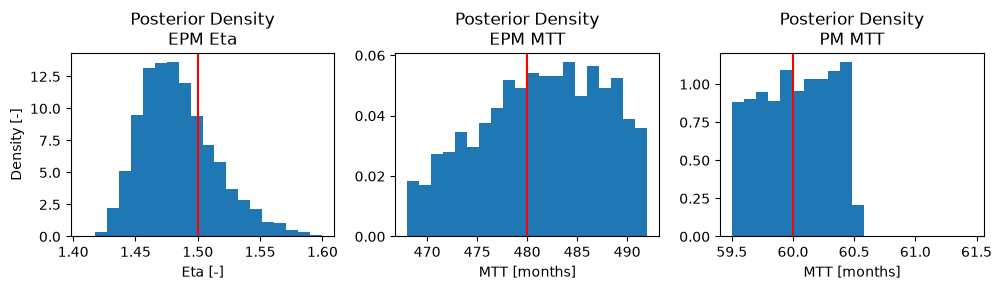

In [8]:
# define true parameters
epm_mtt_true = 12 * 40 # 40 years
epm_eta_true = 1.5
pm_mtt_true = 12 * 5 # 5 years (faster than EPM)

fig, ax = plt.subplots(1, 3, figsize=(10, 3))

_ = ax[0].hist(
    res["samples"][:, 0],
    bins=20,
    density=True,
    label="EPM Eta"
)
ax[0].axvline(epm_eta_true, color="red", label="True")
ax[0].set_title("Posterior Density\nEPM Eta")
ax[0].set_xlabel("Eta [-]")
ax[0].set_ylabel("Density [-]")

_ = ax[1].hist(
    res["samples"][:, 1],
    bins=20,
    density=True,
    label="EPM MTT"
)
ax[1].axvline(epm_mtt_true, color="red", label="True")
ax[1].set_title("Posterior Density\nEPM MTT")
ax[1].set_xlabel("MTT [months]")

_ = ax[2].hist(
    res["samples"][:, 2],
    bins=20,
    density=True,
    label="PM MTT"
)
ax[2].axvline(pm_mtt_true, color="red", label="True")
ax[2].set_title("Posterior Density\nPM MTT")
ax[2].set_xlabel("MTT [months]")

plt.tight_layout()

The posterior of `epm.mtt` is cut off at both bounds (39 and 41 years, i.e. 468 and 492 months): in this tutorial, the narrow bounds and not the observations limit its range.

In [9]:
res["sims"].reshape(-1, res["sims"].shape[2]).shape

(32000, 600)

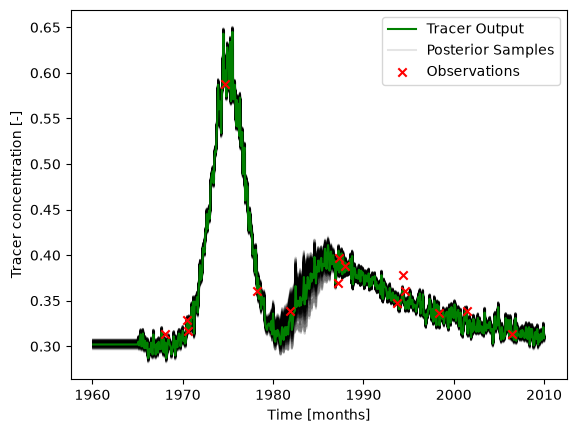

In [10]:
### plot input series, true output series, observations, and´
# calibrated output

# create figure
fig, ax = plt.subplots(1, 1)
# plot output series
ax.plot(
    timesteps,
    output_series,
    label="Tracer Output",
    c="green",
    zorder=1000000
)
# plot calibrated results
sims_ = res["sims"].reshape(-1, res["sims"].shape[2])[::100, :]
for i in range(len(sims_)):
    if i < len(sims_) - 1:
        ax.plot(
            timesteps,
            sims_[i, :],
            # label="Calibration",
            c="black",
            alpha=0.1
        )
    else:
        ax.plot(
            timesteps,
            sims_[i, :],
            label="Posterior Samples",
            c="black",
            alpha=0.1
        )
# plot observations
ax.scatter(
    timesteps,
    obs_series,
    label="Observations",
    color="red",
    marker="x",
    zorder=100000000
)
ax.set_xlabel("Time [months]")
ax.set_ylabel("Tracer concentration [-]")
ax.legend()
plt.show()